**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Brayan Ortega Armendáriz
*   MATRÍCULA: ---A01561888-------------------------

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [2]:
%pip install seaborn scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 2.1 MB/s  0:00:09m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [seaborn]m1/2 [seaborn]
Note: you may need to restart the kernel to use updated packages.


In [5]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [7]:
# Cargar todos los registros del archivo
loan_df = pd.read_csv("personal_loan.csv")

# Convertir ID en el índice del DataFrame
loan_df = loan_df.set_index("ID")

# Obtener las columnas según el tipo inferido por pandas
columnasNumericas = loan_df.select_dtypes(
    include=np.number
).columns.tolist()

columnasTexto = loan_df.select_dtypes(
    include="str"
).columns.tolist()

# Guardar la cantidad de columnas de cada tipo
cantidadColumnasNumericas = len(columnasNumericas)
cantidadColumnasTexto = len(columnasTexto)

# Mostrar las dimensiones para comprobar la carga completa
print(f"Dimensiones del DataFrame: {loan_df.shape}")

# Mostrar el resumen solicitado
print("\nResumen del DataFrame:")
loan_df.info()

# Mostrar la clasificación de las columnas
print("\nColumnas numéricas:")
print(columnasNumericas)

print("\nColumnas de texto:")
print(columnasTexto)

print(f"\nCantidad de columnas numéricas: {cantidadColumnasNumericas}")
print(f"Cantidad de columnas de texto: {cantidadColumnasTexto}")

Dimensiones del DataFrame: (5037, 13)

Resumen del DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   str    
 9   Securities Account  5037 non-null   str    
 10  CD Account          5037 non-null   str    
 11  Online              5037 non-null   str    
 12  CreditCard          5037 non-null   str    
dtypes: float64(2), int64(6), str(5)
memory usage: 511.7 KB

Columnas numéricas:
['Age', 'Experience', 'Inc

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [19]:

# EJERCICIO 2: ESTADÍSTICAS Y LIMPIEZA DE VARIABLES NUMÉRICAS



# Conservamos una copia de los datos sin limpiar.
# La condición evita reemplazar esta copia si ejecutamos
# nuevamente la celda después de haber limpiado loan_df.
if "loan_df_original" not in globals():
    loan_df_original = loan_df.copy()


# Cada vez que ejecutemos esta celda, empezaremos nuevamente
# desde los datos originales del ejercicio 1.
loan_df = loan_df_original.copy()


# Guardamos la cantidad inicial porque la necesitaremos para
# calcular el número y el porcentaje de registros eliminados.
cantidadRegistrosIniciales = loan_df.shape[0]


estadisticasNumericas = loan_df.describe().T

print("Estadísticas descriptivas iniciales:")
display(estadisticasNumericas)


# 1. EDADES SUPERIORES A 100 AÑOS


# La comparación se realiza elemento por elemento.
# El resultado es una Serie booleana:
# True  -> la edad supera los 100 años.
# False -> la edad no supera los 100 años.
edadInvalida = loan_df["Age"] > 100


# loc utiliza la Serie booleana para recuperar solamente
# los registros en los que la condición es verdadera.
registrosEdadInvalida = loan_df.loc[edadInvalida]

print("\nRegistros con edad superior a 100 años:")
display(registrosEdadInvalida)


# 2. REVISIÓN DEL RESTO DE LAS VARIABLES NUMÉRICAS


# La experiencia laboral no puede ser negativa.
experienciaInvalida = loan_df["Experience"] < 0

# identificar los códigos que quedan fuera de ese intervalo.
codigoPostalInvalido = ~loan_df["ZIP Code"].between(
    10000,
    99999
)

# Los valores negativos son imposibles.
familiaInvalida = ~loan_df["Family"].between(
    1,
    4
)


# isin() comprueba si cada valor pertenece al conjunto permitido.
# El símbolo ~ selecciona los valores que no son 1, 2 o 3.
educacionInvalida = ~loan_df["Education"].isin(
    [1, 2, 3]
)


# Creamos una tabla resumida para documentar las inconsistencias
# encontradas, los valores observados y su justificación.
resumenInconsistencias = pd.DataFrame({
    "Variable": [
        "Age",
        "Experience",
        "ZIP Code",
        "Family",
        "Education"
    ],

    "Criterio aplicado": [
        "Age > 100",
        "Experience < 0",
        "ZIP Code fuera de 10000-99999",
        "Family fuera de 1-4",
        "Education diferente de 1, 2 o 3"
    ],

    "Valores inválidos encontrados": [
        sorted(loan_df.loc[edadInvalida, "Age"].unique()),
        sorted(loan_df.loc[experienciaInvalida, "Experience"].unique()),
        sorted(loan_df.loc[codigoPostalInvalido, "ZIP Code"].unique()),
        sorted(loan_df.loc[familiaInvalida, "Family"].unique()),
        sorted(loan_df.loc[educacionInvalida, "Education"].unique())
    ],

    "Cantidad de registros": [
        edadInvalida.sum(),
        experienciaInvalida.sum(),
        codigoPostalInvalido.sum(),
        familiaInvalida.sum(),
        educacionInvalida.sum()
    ],

    "Justificación": [
        "Las edades registradas superan un límite plausible para los clientes.",
        "La experiencia laboral no puede expresarse en años negativos.",
        "El valor no contiene los cinco dígitos esperados en un código postal.",
        "La cantidad de integrantes de una familia no puede ser negativa.",
        "La descripción de la variable únicamente permite las categorías 1, 2 y 3."
    ]
})

print("\nResumen de valores inválidos o inconsistentes:")
display(resumenInconsistencias)

# 3. UNIFICAR LAS REGLAS DE ELIMINACIÓN


# El operador | significa OR.
# Una fila será considerada inválida si cumple al menos una
# de las cinco condiciones anteriores.
registroInvalido = (
    edadInvalida
    | experienciaInvalida
    | codigoPostalInvalido
    | familiaInvalida
    | educacionInvalida
)


# sum() cuenta los valores True porque Python interpreta:
# True como 1 y False como 0.
cantidadRegistrosEliminados = registroInvalido.sum()


# Seleccionamos únicamente los registros válidos.
# ~ invierte la máscara:
# las filas inválidas pasan a False y quedan excluidas.
loan_df = loan_df.loc[~registroInvalido].copy()


# Calculamos cuántas filas permanecen después de la limpieza.
cantidadRegistrosFinales = loan_df.shape[0]


# El porcentaje se calcula respecto al número inicial de registros.
porcentajeRegistrosEliminados = (
    cantidadRegistrosEliminados
    / cantidadRegistrosIniciales
) * 100

# 4. RESULTADOS FINALES DEL EJERCICIO


print("\nResultados de la limpieza:")

print(
    f"Registros iniciales: "
    f"{cantidadRegistrosIniciales}"
)

print(
    f"Registros eliminados: "
    f"{cantidadRegistrosEliminados}"
)

print(
    f"Registros restantes: "
    f"{cantidadRegistrosFinales}"
)

print(
    f"Porcentaje eliminado: "
    f"{porcentajeRegistrosEliminados:.2f}%"
)


Estadísticas descriptivas iniciales:


,count,mean,std,min,25%,50%,75%,max
Age,5037.0,45.411356,11.646805,23.0,35.0,45.0,55.0,144.0
Experience,5037.0,20.122494,11.461278,-3.0,10.0,20.0,30.0,43.0
Income,5037.0,73.898352,46.130504,8.0,39.0,64.0,98.0,224.0
ZIP Code,5037.0,93152.865595,2119.637960,9307.0,91911.0,93437.0,94608.0,96651.0
Family,5037.0,2.394679,1.151145,-3.0,1.0,2.0,3.0,4.0
CCAvg,5037.0,1.942404,1.755954,0.0,0.7,1.5,2.6,10.0
Education,5037.0,1.880941,0.843337,1.0,1.0,2.0,3.0,7.3
Mortgage,5037.0,56.500695,101.657580,0.0,0.0,0.0,101.0,635.0



Registros con edad superior a 100 años:


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0



Resumen de valores inválidos o inconsistentes:


,Variable,Criterio aplicado,Valores inválidos encontrados,Cantidad de registros,Justificación
0,Age,Age > 100,"[123, 130, 144]",3,Las edades registradas superan un límite plaus...
1,Experience,Experience < 0,"[-3, -2, -1]",53,La experiencia laboral no puede expresarse en ...
2,ZIP Code,ZIP Code fuera de 10000-99999,[9307],1,El valor no contiene los cinco dígitos esperad...
3,Family,Family fuera de 1-4,"[-3, -1]",2,La cantidad de integrantes de una familia no p...
4,Education,"Education diferente de 1, 2 o 3",[7.3],1,La descripción de la variable únicamente permi...



Resultados de la limpieza:
Registros iniciales: 5037
Registros eliminados: 60
Registros restantes: 4977
Porcentaje eliminado: 1.19%


3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [20]:


# INCISO 1:
# Obtener las estadísticas descriptivas de las variables
# de texto e imprimir las frecuencias de sus categorías.


# limpiado en el problema 2.
columnasTexto = loan_df.select_dtypes(
    include="str"
).columns.tolist()


# describe() aplicado a variables de texto devuelve:
# count  -> cantidad de valores no nulos
# unique -> cantidad de categorías diferentes
# top    -> categoría más frecuente
# freq   -> frecuencia de la categoría más frecuente
#
# .T coloca cada variable como una fila.
estadisticasTexto = loan_df[
    columnasTexto
].describe().T


print("Estadísticas descriptivas de las variables de texto:")
display(estadisticasTexto)


# value_counts() cuenta cuántas veces aparece cada categoría.
# El ciclo repite el conteo para cada columna de texto.
for columna in columnasTexto:

    print(f"\nFrecuencias de la variable {columna}:")

    frecuencias = (
        loan_df[columna]
        .value_counts(dropna=False)
        .rename_axis("Categoría")
        .reset_index(name="Frecuencia")
    )

    display(frecuencias)


# ============================================================
# INCISO 2:
# Unificar los valores binarios para que coincidan con
# la descripción de las variables al inicio del notebook.
#
# Descripción establecida:
# 1 = Sí
# 0 = No
# ============================================================


# Estas son las variables binarias identificadas en la
# descripción inicial del dataset.
columnasBinarias = [
    "Personal Loan",
    "Securities Account",
    "CD Account",
    "Online",
    "CreditCard"
]


# El archivo utiliza cuatro representaciones diferentes:
# "0", "1", "No" y "Yes".
#
# El diccionario establece la equivalencia:
# "0"  y "No"  representan 0.
# "1"  y "Yes" representan 1.
mapaBinario = {
    "0": 0,
    "No": 0,
    "1": 1,
    "Yes": 1
}


# Recorremos cada variable binaria para aplicar la misma limpieza.
for columna in columnasBinarias:

    # astype("str") garantiza que todos los valores sean texto
    
    # astype("int64") almacena finalmente el resultado como entero.
    loan_df[columna] = (
        loan_df[columna]
        .astype("str")
        .str.strip()
        .map(mapaBinario)
        .astype("int64")
    )


# ============================================================
# COMPROBACIÓN DEL RESULTADO
# ============================================================


# Mostramos las frecuencias después de la unificación.
# Cada columna debe contener únicamente las categorías 0 y 1.
print("\nFrecuencias después de unificar los valores binarios:")

for columna in columnasBinarias:

    print(f"\n{columna}:")

    frecuenciasUnificadas = (
        loan_df[columna]
        .value_counts()
        .sort_index()
        .rename_axis("Categoría")
        .reset_index(name="Frecuencia")
    )

    display(frecuenciasUnificadas)


# Mostramos los tipos finales de las columnas procesadas.
print("\nTipos de datos después de la unificación:")
print(loan_df[columnasBinarias].dtypes)

Estadísticas descriptivas de las variables de texto:


,count,unique,top,freq
Personal Loan,4977,4,0,3475
Securities Account,4977,4,No,2693
CD Account,4977,4,No,2462
Online,4977,4,Yes,1700
CreditCard,4977,4,0,2628



Frecuencias de la variable Personal Loan:


,Categoría,Frecuencia
0,0,3475
1,No,1017
2,Yes,368
3,1,117



Frecuencias de la variable Securities Account:


...


Online:


,Categoría,Frecuencia
0,0,2002
1,1,2975



CreditCard:


,Categoría,Frecuencia
0,0,3513
1,1,1464



Tipos de datos después de la unificación:
Personal Loan         int64
Securities Account    int64
CD Account            int64
Online                int64
CreditCard            int64
dtype: object


4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [10]:
# ============================================================
# PROBLEMA 4
# Verificar y eliminar registros duplicados.
# Reiniciar el índice después de las eliminaciones.
# ============================================================


# Guardamos la cantidad de registros que existen antes
# de comenzar la eliminación de duplicados.
cantidadAntesDuplicados = loan_df.shape[0]


# ============================================================
# INCISO 1:
# Verificar si existen registros duplicados.
# ============================================================


# duplicated(keep=False) compara todas las columnas.
#
# keep=False marca como True todas las filas que pertenecen
# a un grupo duplicado, incluyendo la primera aparición.
#
# El índice ID no participa en la comparación porque no es
# una columna del DataFrame.
mascaraGruposDuplicados = loan_df.duplicated(
    keep=False
)


# Recuperamos todas las filas pertenecientes a grupos duplicados.
registrosDuplicados = loan_df.loc[
    mascaraGruposDuplicados
].sort_values(
    by=loan_df.columns.tolist()
)


# Esta cantidad incluye tanto los registros originales
# como sus copias repetidas.
cantidadFilasEnGruposDuplicados = (
    mascaraGruposDuplicados.sum()
)


# duplicated() utiliza keep="first" de manera predeterminada.
# Esto conserva la primera aparición y marca solamente
# las copias adicionales que deben eliminarse.
mascaraDuplicadosEliminar = loan_df.duplicated(
    keep="first"
)


# Contamos únicamente las copias que se eliminarán.
cantidadDuplicadosEliminar = (
    mascaraDuplicadosEliminar.sum()
)


print(
    "Filas que forman parte de grupos duplicados:",
    cantidadFilasEnGruposDuplicados
)

print(
    "Copias duplicadas que deben eliminarse:",
    cantidadDuplicadosEliminar
)

print("\nRegistros pertenecientes a grupos duplicados:")
display(registrosDuplicados)


# ============================================================
# INCISO 2:
# Eliminar los registros duplicados.
# ============================================================


# drop_duplicates() conserva la primera aparición de cada
# registro y elimina las copias posteriores.
loan_df = loan_df.drop_duplicates(
    keep="first"
)


# Calculamos cuántas filas permanecen después de eliminar
# las copias duplicadas.
cantidadDespuesDuplicados = loan_df.shape[0]


# ============================================================
# INCISO 3:
# Reiniciar el índice para mantener una secuencia continua.
# ============================================================


# reset_index(drop=True) crea un índice nuevo:
# 0, 1, 2, 3, ..., número final de registros.
#
# drop=True evita recuperar el ID anterior como una columna,
# ya que esos identificadores dejaron de ser continuos después
# de las eliminaciones.
loan_df = loan_df.reset_index(
    drop=True
)


# Nombramos ID al nuevo índice continuo.
loan_df.index.name = "ID"


# Comprobamos que el índice final vaya desde cero hasta
# la última fila sin saltos intermedios.
indiceEsperado = pd.RangeIndex(
    start=0,
    stop=len(loan_df),
    step=1,
    name="ID"
)

indiceContinuo = loan_df.index.equals(
    indiceEsperado
)


# ============================================================
# RESULTADOS
# ============================================================

print("\nResultados de la eliminación de duplicados:")

print(
    f"Registros antes de eliminar duplicados: "
    f"{cantidadAntesDuplicados}"
)

print(
    f"Registros duplicados eliminados: "
    f"{cantidadDuplicadosEliminar}"
)

print(
    f"Registros después de eliminar duplicados: "
    f"{cantidadDespuesDuplicados}"
)

print(
    f"¿El índice es continuo?: "
    f"{indiceContinuo}"
)

print(
    f"Primer índice: "
    f"{loan_df.index.min()}"
)

print(
    f"Último índice: "
    f"{loan_df.index.max()}"
)

Filas que forman parte de grupos duplicados: 72
Copias duplicadas que deben eliminarse: 36

Registros pertenecientes a grupos duplicados:


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
1160,28,1,40,95134,1,2.0,2.0,0,0,1,0,1,0
5031,28,1,40,95134,1,2.0,2.0,0,0,1,0,1,0
3673,34,9,65,95134,4,1.3,1.0,0,0,0,0,0,1
5032,34,9,65,95134,4,1.3,1.0,0,0,0,0,0,1
2101,35,5,203,95032,1,10.0,3.0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5026,64,37,138,94709,2,2.8,2.0,0,1,0,0,1,0
767,64,39,38,92024,1,1.1,3.0,108,0,0,0,0,0
5016,64,39,38,92024,1,1.1,3.0,108,0,0,0,0,0



Resultados de la eliminación de duplicados:
Registros antes de eliminar duplicados: 4977
Registros duplicados eliminados: 36
Registros después de eliminar duplicados: 4941
¿El índice es continuo?: True
Primer índice: 0
Último índice: 4940


5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [11]:
# ============================================================
# PROBLEMA 5
# Ajustar los tipos de datos según la naturaleza estadística
# de cada variable.
# ============================================================


# ============================================================
# INCISO 1:
# Convertir ZIP Code en una variable nominal de tipo object.
# ============================================================


# ZIP Code contiene números, pero estos funcionan como
# identificadores geográficos, no como cantidades.
#
# astype("object") evita que pandas la incluya como una
# variable numérica en los análisis posteriores.
loan_df["ZIP Code"] = loan_df[
    "ZIP Code"
].astype("object")


# ============================================================
# INCISO 2:
# Convertir Education en una variable ordinal de tipo category
# con el orden 1 < 2 < 3.
# ============================================================


# Definimos el tipo categórico y su orden explícito:
# 1 = graduado
# 2 = universitario
# 3 = posgrado
tipoEducacion = pd.CategoricalDtype(
    categories=[1, 2, 3],
    ordered=True
)


# Después de eliminar el valor inválido 7.3 en el problema 2,
# convertimos los valores válidos primero en enteros.
#
# Posteriormente aplicamos el tipo categórico ordenado.
loan_df["Education"] = (
    loan_df["Education"]
    .astype("int64")
    .astype(tipoEducacion)
)


# ============================================================
# INCISO 3:
# Convertir las variables binarias en category.
# ============================================================


# Estas columnas ya contienen únicamente 0 y 1 gracias
# a la limpieza realizada en el problema 3.
columnasBinarias = [
    "Personal Loan",
    "Securities Account",
    "CD Account",
    "Online",
    "CreditCard"
]


# Convertimos conjuntamente las cinco columnas.
#
# Los valores visibles seguirán siendo 0 y 1, pero pandas
# los interpretará como categorías y no como cantidades.
loan_df[columnasBinarias] = loan_df[
    columnasBinarias
].astype("category")


# ============================================================
# INCISO 4:
# Crear num_cols con los nombres de las variables numéricas.
# ============================================================


# np.number incluye los tipos numéricos reconocidos por
# NumPy y pandas, como int64 y float64.
#
# .columns obtiene los nombres y tolist() crea una lista.
num_cols = (
    loan_df
    .select_dtypes(include=np.number)
    .columns
    .tolist()
)


# ============================================================
# INCISO 5:
# Crear cat_cols con los nombres de las variables categóricas.
# ============================================================


# Se incluyen:
# object   -> ZIP Code
# category -> Education y las cinco variables binarias
# str      -> permite que el código sea compatible con el
#             manejo moderno de texto de pandas.
cat_cols = (
    loan_df
    .select_dtypes(
        include=["object", "str", "category"]
    )
    .columns
    .tolist()
)


# ============================================================
# COMPROBACIÓN DE LAS CONVERSIONES
# ============================================================


print("Tipos de datos después de las conversiones:")
print(loan_df.dtypes)


print("\nVariables numéricas:")
print(num_cols)


print("\nVariables categóricas:")
print(cat_cols)


print("\nCategorías de Education:")
print(
    loan_df["Education"].cat.categories
)


print(
    "¿Education tiene un orden definido?:",
    loan_df["Education"].cat.ordered
)


print("\nCategorías de las variables binarias:")

for columna in columnasBinarias:
    print(
        f"{columna}: "
        f"{loan_df[columna].cat.categories.tolist()}"
    )

Tipos de datos después de las conversiones:
Age                      int64
Experience               int64
Income                   int64
ZIP Code                object
Family                   int64
CCAvg                  float64
Education             category
Mortgage                 int64
Personal Loan         category
Securities Account    category
CD Account            category
Online                category
CreditCard            category
dtype: object

Variables numéricas:
['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']

Variables categóricas:
['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']

Categorías de Education:
Index([1, 2, 3], dtype='int64')
¿Education tiene un orden definido?: True

Categorías de las variables binarias:
Personal Loan: [0, 1]
Securities Account: [0, 1]
CD Account: [0, 1]
Online: [0, 1]
CreditCard: [0, 1]


# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [12]:
# ============================================================
# PROBLEMA 6
# Obtener estadísticas descriptivas de las variables numéricas,
# incluyendo asimetría y curtosis.
# ============================================================


# ============================================================
# INCISO 1:
# Obtener nuevamente las estadísticas descriptivas de las
# variables numéricas.
# ============================================================


# num_cols fue creada en el problema 5 y contiene:
# Age, Experience, Income, Family, CCAvg y Mortgage.
#
# describe() calcula las estadísticas descriptivas tradicionales.
# .T coloca cada variable como una fila.
estadisticasNumericas = (
    loan_df[num_cols]
    .describe()
    .T
)


# skew() calcula el coeficiente de asimetría de cada variable.
# Los resultados se agregan como una nueva columna.
estadisticasNumericas["Asimetría"] = (
    loan_df[num_cols].skew()
)


# kurt() calcula la curtosis excedente.
# En esta medida, una distribución normal tiene curtosis
# aproximadamente igual a cero.
estadisticasNumericas["Curtosis"] = (
    loan_df[num_cols].kurt()
)


print(
    "Estadísticas descriptivas con asimetría y curtosis:"
)

display(
    estadisticasNumericas.round(3)
)


# ============================================================
# INCISO 2:
# Clasificar Age, Income y Mortgage según su asimetría.
# ============================================================


# Esta función recibe un coeficiente de asimetría y devuelve
# una descripción según su magnitud y dirección.
def clasificarAsimetria(valor):

    # Valores entre -0.5 y 0.5 indican una distribución
    # aproximadamente equilibrada.
    if -0.5 <= valor <= 0.5:
        return "Aproximadamente simétrica"

    # Valores mayores que 1 indican una cola pronunciada
    # hacia los valores altos.
    elif valor > 1:
        return "Asimetría positiva fuerte"

    # Valores entre 0.5 y 1 indican una cola moderada
    # hacia los valores altos.
    elif valor > 0.5:
        return "Asimetría positiva moderada"

    # Valores menores que -1 indican una cola pronunciada
    # hacia los valores bajos.
    elif valor < -1:
        return "Asimetría negativa fuerte"

    # Los valores restantes están entre -1 y -0.5.
    else:
        return "Asimetría negativa moderada"


# ============================================================
# INCISO 3:
# Clasificar Age, Income y Mortgage según su curtosis.
# ============================================================


# Esta función recibe el coeficiente de curtosis excedente.
def clasificarCurtosis(valor):

    # Una curtosis cercana a cero se considera aproximadamente
    # mesocúrtica, similar a una distribución normal.
    if -0.5 <= valor <= 0.5:
        return "Aproximadamente mesocúrtica"

    # Una curtosis positiva indica colas más pesadas y mayor
    # presencia potencial de valores extremos.
    elif valor > 0.5:
        return "Leptocúrtica"

    # Una curtosis negativa indica colas más ligeras.
    else:
        return "Platicúrtica"


# Estas son las variables que el ejercicio pide clasificar.
variablesClasificar = [
    "Age",
    "Income",
    "Mortgage"
]


# Creamos un DataFrame para almacenar los coeficientes y
# sus correspondientes clasificaciones.
clasificacionVariables = pd.DataFrame(
    index=variablesClasificar
)


# Calculamos la asimetría únicamente para las tres variables.
clasificacionVariables["Asimetría"] = (
    loan_df[variablesClasificar].skew()
)


# apply() envía cada coeficiente a la función de clasificación.
clasificacionVariables[
    "Clasificación de asimetría"
] = (
    clasificacionVariables["Asimetría"]
    .apply(clasificarAsimetria)
)


# Calculamos la curtosis de las tres variables.
clasificacionVariables["Curtosis"] = (
    loan_df[variablesClasificar].kurt()
)


# Clasificamos cada coeficiente de curtosis.
clasificacionVariables[
    "Clasificación de curtosis"
] = (
    clasificacionVariables["Curtosis"]
    .apply(clasificarCurtosis)
)


print(
    "\nClasificación de Age, Income y Mortgage:"
)

display(
    clasificacionVariables.round(3)
)

Estadísticas descriptivas con asimetría y curtosis:


,count,mean,std,min,25%,50%,75%,max,Asimetría,Curtosis
Age,4941.0,45.560,11.316,24.0,36.0,46.0,55.0,67.0,-0.023,-1.162
Experience,4941.0,20.335,11.308,0.0,11.0,20.0,30.0,43.0,-0.015,-1.135
Income,4941.0,73.827,46.107,8.0,39.0,64.0,98.0,224.0,0.842,-0.046
Family,4941.0,2.392,1.148,1.0,1.0,2.0,3.0,4.0,0.159,-1.404
CCAvg,4941.0,1.936,1.748,0.0,0.7,1.5,2.6,10.0,1.595,2.636
Mortgage,4941.0,56.664,101.875,0.0,0.0,0.0,101.0,635.0,2.104,4.760



Clasificación de Age, Income y Mortgage:


,Asimetría,Clasificación de asimetría,Curtosis,Clasificación de curtosis
Age,-0.023,Aproximadamente simétrica,-1.162,Platicúrtica
Income,0.842,Asimetría positiva moderada,-0.046,Aproximadamente mesocúrtica
Mortgage,2.104,Asimetría positiva fuerte,4.760,Leptocúrtica


7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

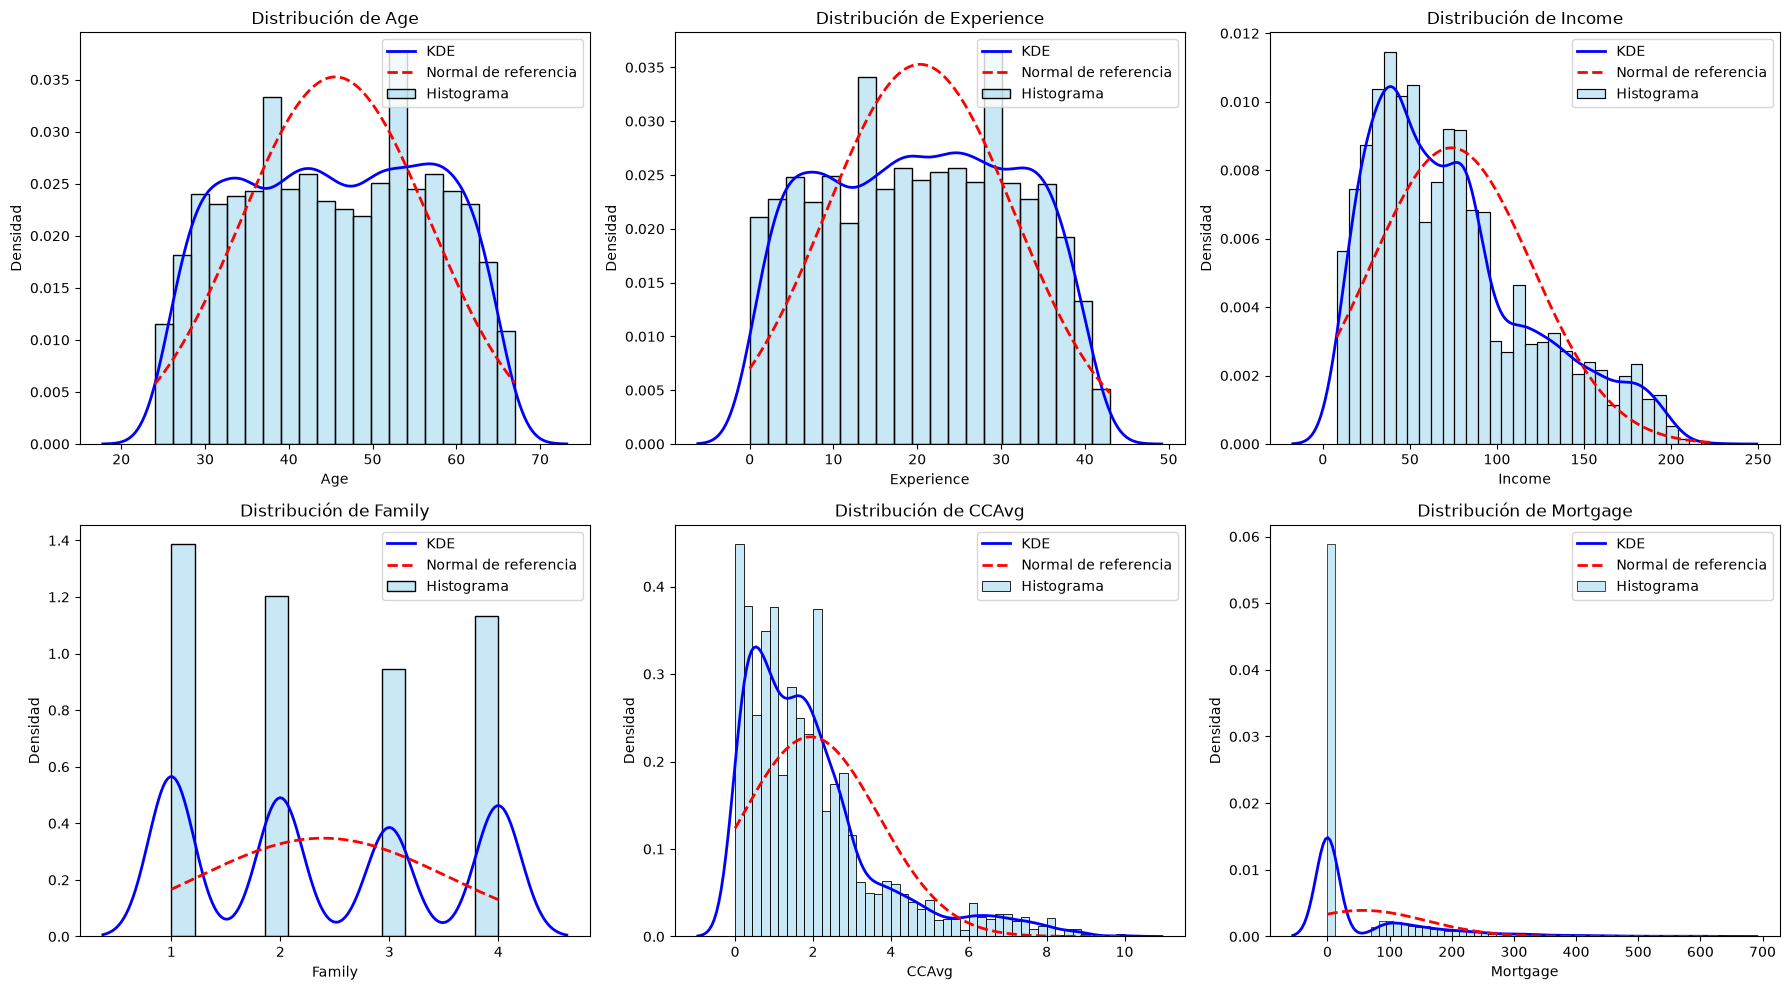

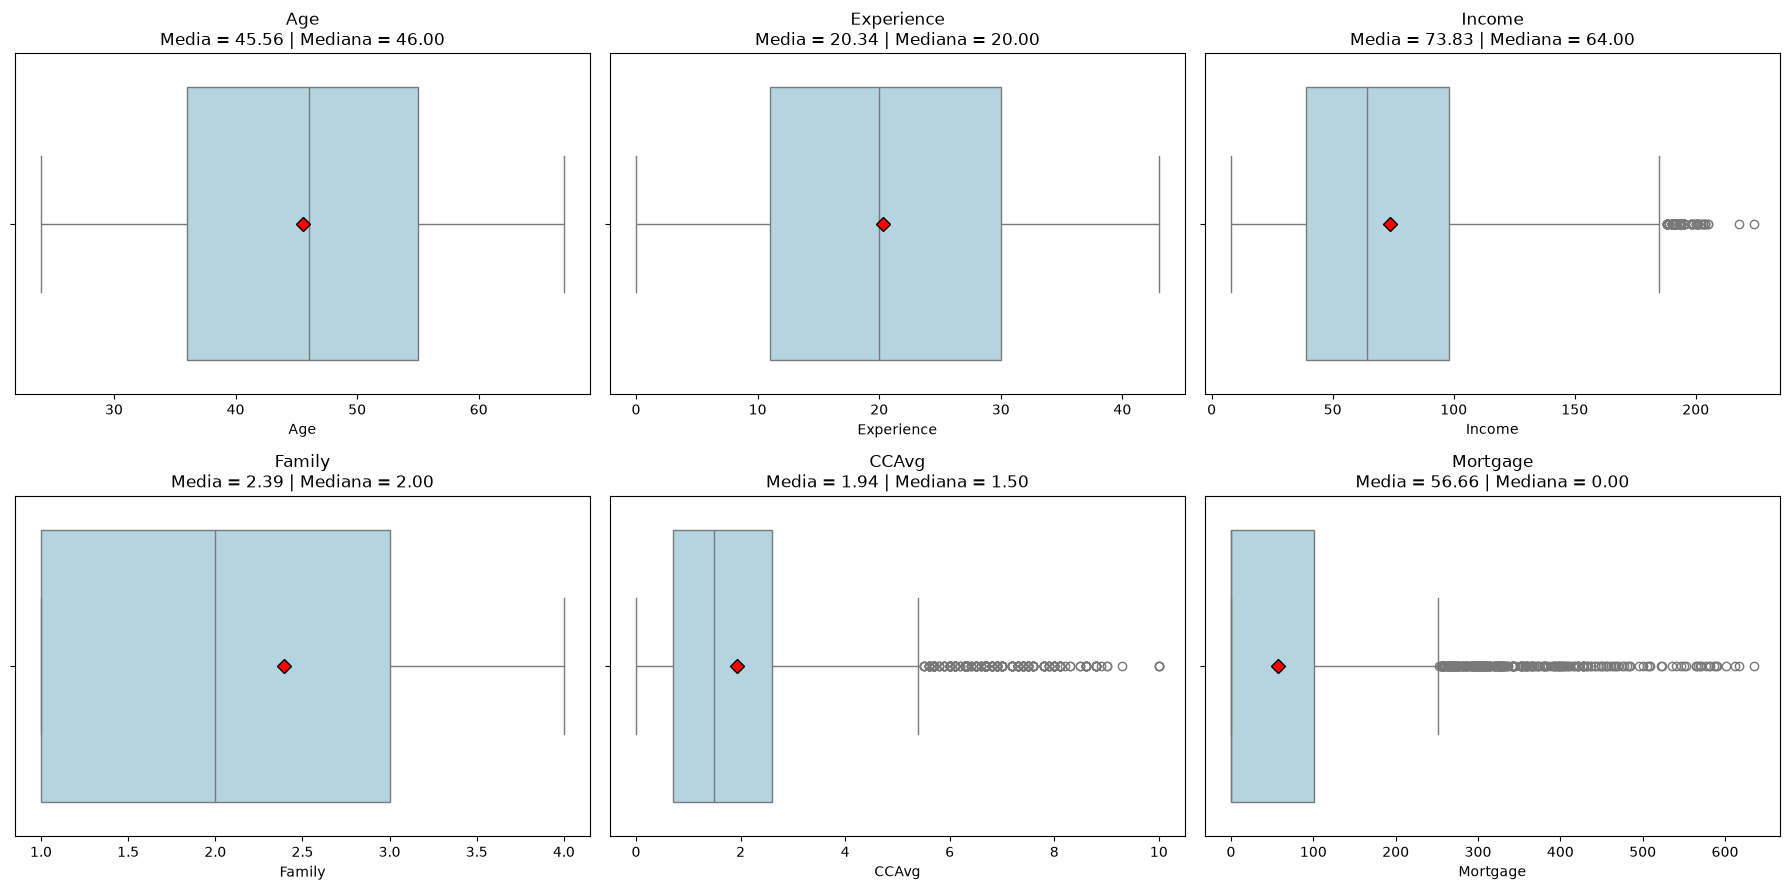

Comparación entre media, mediana, asimetría y curtosis:


,Media,Mediana,Asimetría,Curtosis,Media - Mediana
Age,45.560,46.0,-0.023,-1.162,-0.440
Experience,20.335,20.0,-0.015,-1.135,0.335
Income,73.827,64.0,0.842,-0.046,9.827
Family,2.392,2.0,0.159,-1.404,0.392
CCAvg,1.936,1.5,1.595,2.636,0.436
Mortgage,56.664,0.0,2.104,4.760,56.664



Variables clasificadas en el problema 6:


,Media,Mediana,Asimetría,Curtosis,Media - Mediana
Age,45.560,46.0,-0.023,-1.162,-0.440
Income,73.827,64.0,0.842,-0.046,9.827
Mortgage,56.664,0.0,2.104,4.760,56.664


In [13]:
# ============================================================
# PROBLEMA 7
# Analizar visualmente las distribuciones numéricas.
# ============================================================


# ============================================================
# INCISO 1:
# Crear un histograma para cada variable numérica,
# incluyendo KDE y una distribución normal de referencia.
# ============================================================


# Creamos una cuadrícula de 2 filas y 3 columnas.
# Como num_cols contiene seis variables, cada una tendrá
# su propio espacio gráfico o Axes.
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18, 10)
)


# flatten() transforma la cuadrícula de Axes:
#
# [[axes[0,0], axes[0,1], axes[0,2]],
#  [axes[1,0], axes[1,1], axes[1,2]]]
#
# en una secuencia de seis posiciones que puede recorrerse
# fácilmente mediante un ciclo.
axes = axes.flatten()


# zip() empareja cada variable numérica con un Axes.
#
# Primera repetición:
# variable = "Age"
# ax = axes[0]
#
# Segunda repetición:
# variable = "Experience"
# ax = axes[1]
for variable, ax in zip(num_cols, axes):

    # Seleccionamos la Serie correspondiente a la variable.
    datos = loan_df[variable]


    # Calculamos la media y desviación estándar necesarias
    # para construir la distribución normal de referencia.
    media = datos.mean()
    desviacion = datos.std()


    # histplot() crea el histograma.
    #
    # stat="density" hace que el eje Y represente densidad
    # y no cantidad de registros. Esto es indispensable para
    # poder comparar el histograma con las curvas KDE y normal.
    #
    # bins="auto" permite que NumPy determine una cantidad
    # apropiada de intervalos según los datos.
    sns.histplot(
        data=loan_df,
        x=variable,
        bins="auto",
        stat="density",
        color="skyblue",
        alpha=0.45,
        ax=ax,
        label="Histograma"
    )


    # kdeplot() crea una estimación suavizada de la
    # distribución observada realmente en los datos.
    sns.kdeplot(
        data=loan_df,
        x=variable,
        color="blue",
        linewidth=2,
        ax=ax,
        label="KDE"
    )


    # linspace() crea 300 posiciones igualmente espaciadas
    # entre el valor mínimo y el máximo de la variable.
    valoresX = np.linspace(
        datos.min(),
        datos.max(),
        300
    )


    # norm.pdf() calcula la densidad que tendría una
    # distribución normal con la misma media y desviación
    # estándar que la variable analizada.
    curvaNormal = norm.pdf(
        valoresX,
        loc=media,
        scale=desviacion
    )


    # Dibujamos la curva normal sobre el histograma.
    ax.plot(
        valoresX,
        curvaNormal,
        color="red",
        linestyle="--",
        linewidth=2,
        label="Normal de referencia"
    )


    # Agregamos contexto a cada gráfica.
    ax.set_title(
        f"Distribución de {variable}"
    )

    ax.set_xlabel(variable)
    ax.set_ylabel("Densidad")
    ax.legend()


# Ajustamos automáticamente los espacios para evitar
# que los títulos y etiquetas se superpongan.
plt.tight_layout()

# Mostramos la figura completa.
plt.show()


# ============================================================
# INCISO 2:
# Crear un boxplot individual para cada variable numérica
# e incluir la media.
# ============================================================


fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18, 9)
)

axes = axes.flatten()


for variable, ax in zip(num_cols, axes):

    datos = loan_df[variable]

    media = datos.mean()
    mediana = datos.median()


    # boxplot() muestra mediana, cuartiles, dispersión
    # y posibles valores atípicos.
    #
    # showmeans=True agrega la media al boxplot.
    #
    # meanprops configura la apariencia del símbolo
    # utilizado para representar la media.
    sns.boxplot(
        x=datos,
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "red",
            "markeredgecolor": "black",
            "markersize": 7
        },
        color="lightblue",
        ax=ax
    )


    # El título muestra los valores exactos para facilitar
    # la comparación entre la media y la mediana.
    ax.set_title(
        f"{variable}\n"
        f"Media = {media:.2f} | "
        f"Mediana = {mediana:.2f}"
    )

    ax.set_xlabel(variable)


plt.tight_layout()
plt.show()


# ============================================================
# INCISO 3:
# Comparar numéricamente la media, la mediana,
# la asimetría y la curtosis.
# ============================================================


# Creamos una tabla donde cada fila corresponde a una
# variable numérica.
resumenDistribuciones = pd.DataFrame({
    "Media": loan_df[num_cols].mean(),
    "Mediana": loan_df[num_cols].median(),
    "Asimetría": loan_df[num_cols].skew(),
    "Curtosis": loan_df[num_cols].kurt()
})


# Calculamos la diferencia para observar la posición
# de la media con respecto a la mediana.
resumenDistribuciones[
    "Media - Mediana"
] = (
    resumenDistribuciones["Media"]
    - resumenDistribuciones["Mediana"]
)


print(
    "Comparación entre media, mediana, "
    "asimetría y curtosis:"
)

display(
    resumenDistribuciones.round(3)
)


# ============================================================
# INCISO 4:
# Recuperar específicamente Age, Income y Mortgage
# para compararlas con su clasificación del problema 6.
# ============================================================


comparacionVariablesClasificadas = (
    resumenDistribuciones.loc[
        ["Age", "Income", "Mortgage"]
    ]
)


print(
    "\nVariables clasificadas en el problema 6:"
)

display(
    comparacionVariablesClasificadas.round(3)
)

En el caso del histograma Age, presenta una forma la cual resulta ser aproximadamente simétrica, es decir que las edades se distribuyen de una forma similar alrededr del centro, Su asimetría de −0.023 está muy cerca de cero. Su curtosis de −1.162 indica que la distribución es platicúrtica, es decir, más plana y con menos presencia de valores extremos que una distribución normal.

Para el caso de Income, este presenta una asimetría positiva moderada de 0.842. Esto significa que la mayoría de los ingresos se concentra en valores bajos o medios.



8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

Estadísticas descriptivas de las variables categóricas:


,count,unique,top,freq
ZIP Code,4941,467,94720,163
Education,4941,3,1,2079
Personal Loan,4941,2,0,4462
Securities Account,4941,2,0,4426
CD Account,4941,2,0,4640
Online,4941,2,1,2951
CreditCard,4941,2,0,3489


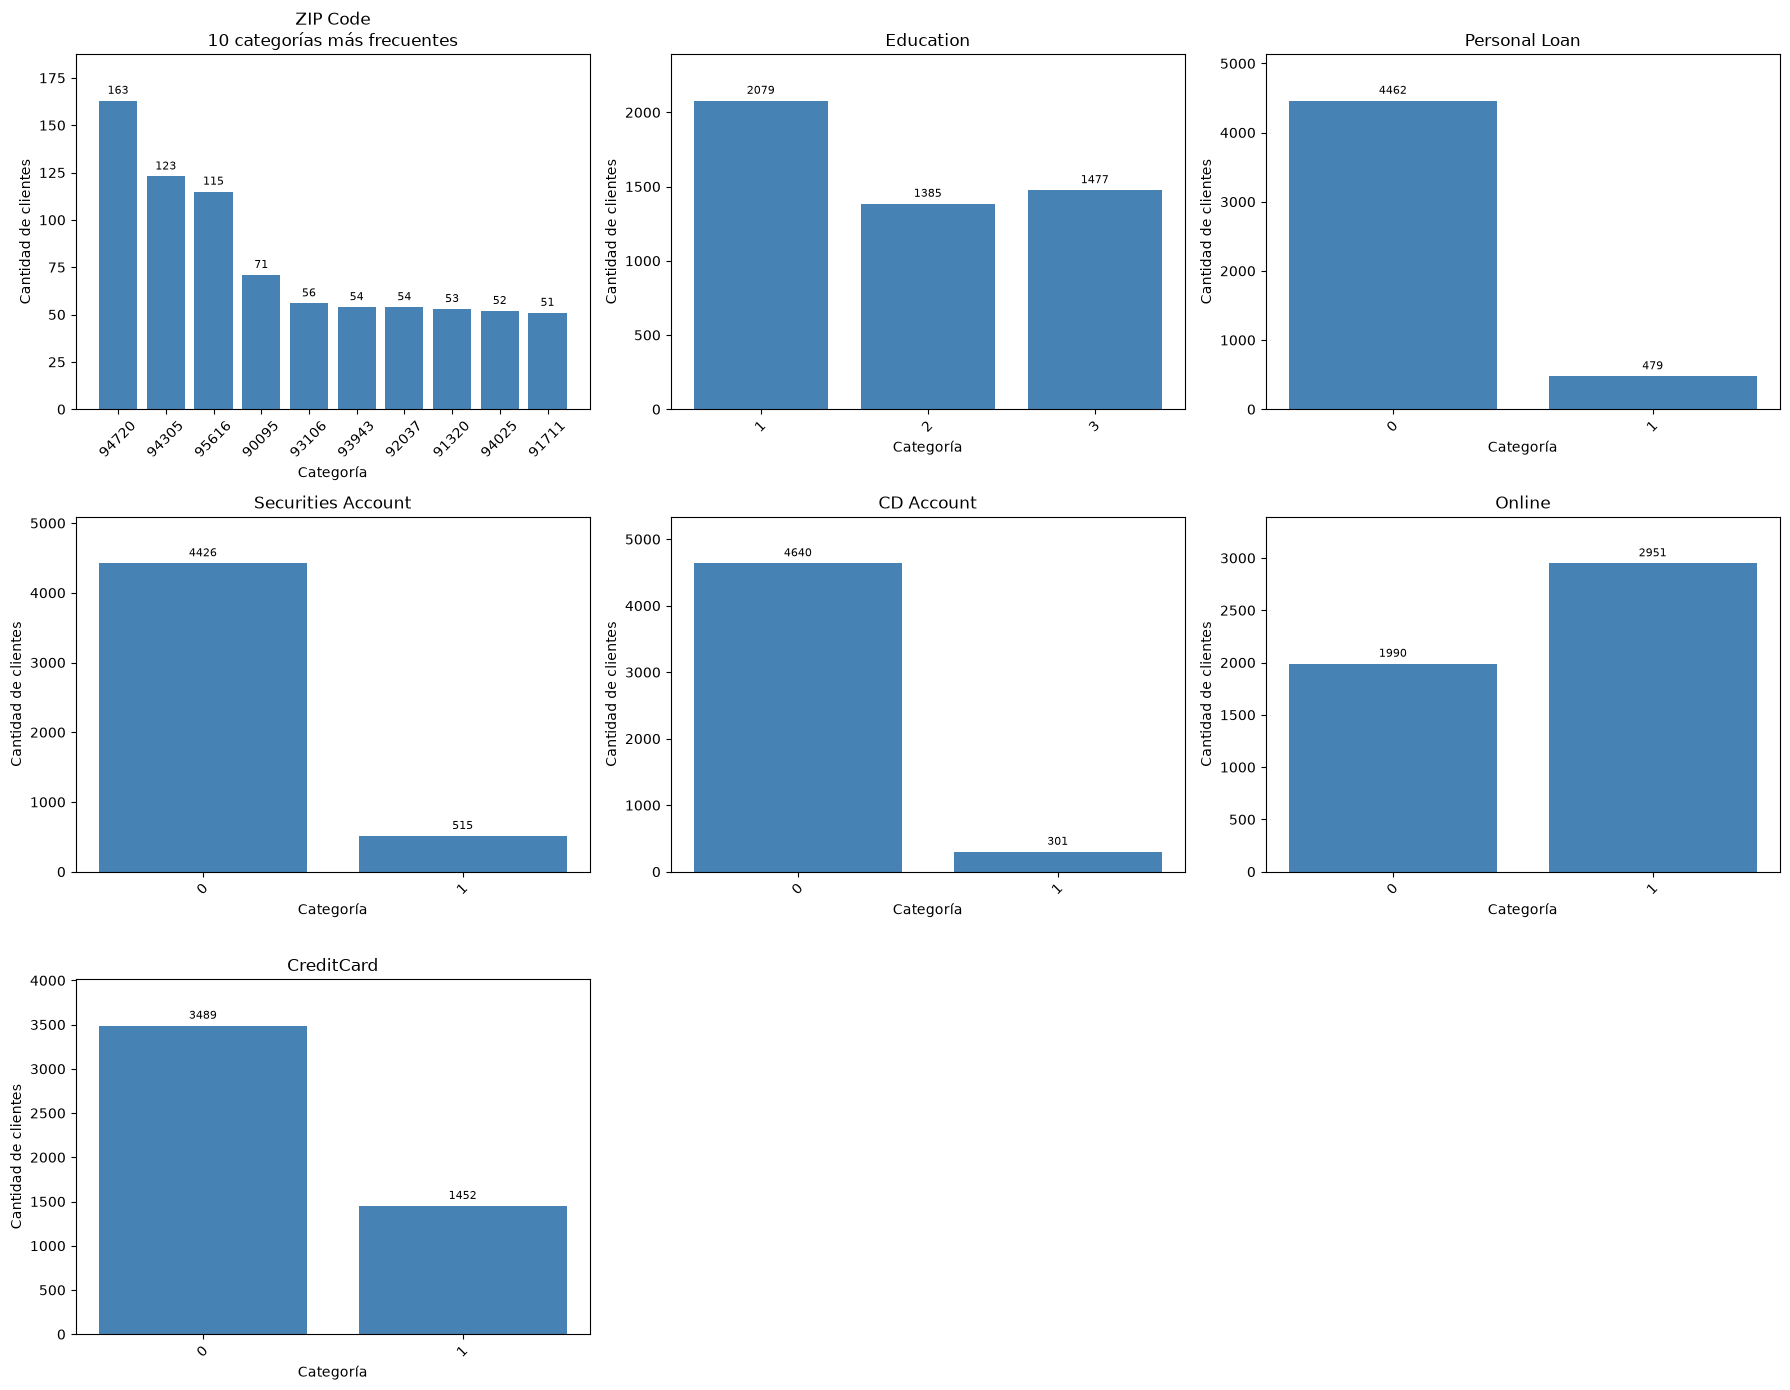

In [15]:

# PROBLEMA 8
# Análisis de las variables categóricas.



# INCISO 1:
# Obtener estadísticas descriptivas.




estadisticasCategoricas = (
    loan_df[cat_cols]
    .describe()
    .T
)


print(
    "Estadísticas descriptivas de las "
    "variables categóricas:"
)

display(
    estadisticasCategoricas
)



fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(18, 14)
)



axes = axes.flatten()


# zip() relaciona cada variable categórica con
# uno de los espacios de la figura.
for variable, ax in zip(cat_cols, axes):

    # nunique() cuenta cuántas categorías diferentes
    # existen en la variable actual.
    cantidadCategorias = (
        loan_df[variable].nunique()
    )


    # Consideramos de alta cardinalidad cualquier variable
    # que tenga más de 10 categorías distintas.
    if cantidadCategorias > 10:


        frecuencias = (
            loan_df[variable]
            .value_counts()
            .head(10)
        )

        titulo = (
            f"{variable}\n"
            f"10 categorías más frecuentes"
        )

    else:


        frecuencias = (
            loan_df[variable]
            .value_counts(sort=False)
        )

        titulo = variable


    etiquetas = [
        str(categoria)
        for categoria in frecuencias.index
    ]



    barras = ax.bar(
        etiquetas,
        frecuencias.values,
        color="steelblue"
    )


    # Mostramos el número de registros encima de cada barra.
    ax.bar_label(
        barras,
        padding=3,
        fontsize=8
    )


    # Agregamos información para interpretar la gráfica.
    ax.set_title(titulo)
    ax.set_xlabel("Categoría")
    ax.set_ylabel("Cantidad de clientes")


    # Giramos las etiquetas para evitar que se encimen.
    ax.tick_params(
        axis="x",
        rotation=45
    )


    # Agregamos espacio encima de las barras para que
    # los números no queden cortados.
    ax.margins(y=0.15)



for ax in axes[len(cat_cols):]:
    fig.delaxes(ax)


# Ajustamos los espacios entre gráficas.
plt.tight_layout()

# Mostramos la figura completa.
plt.show()

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

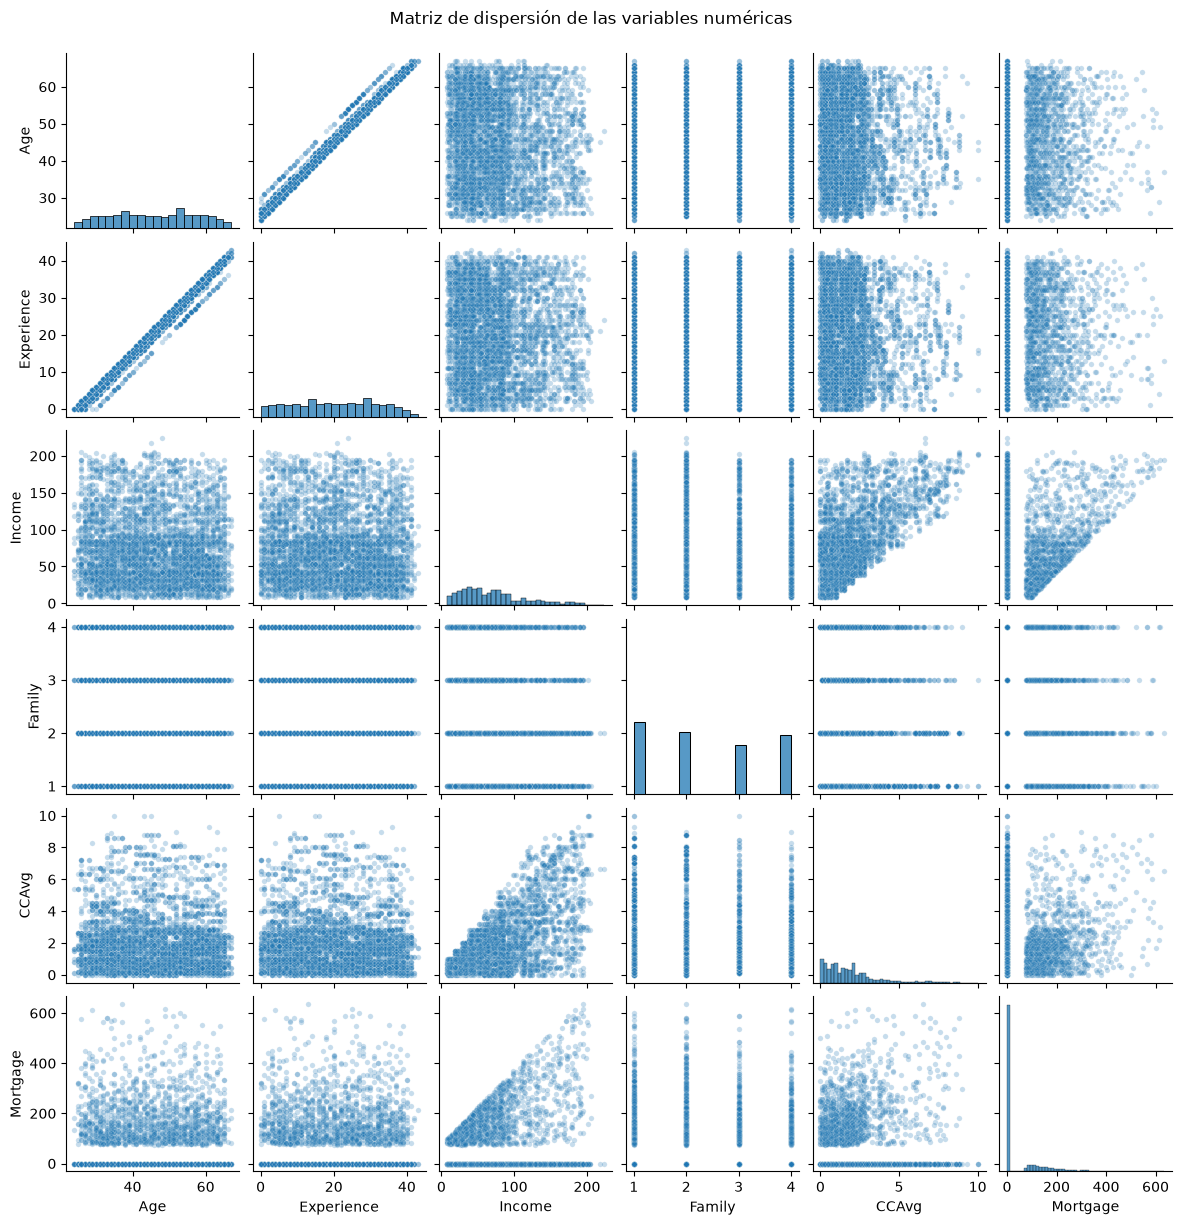

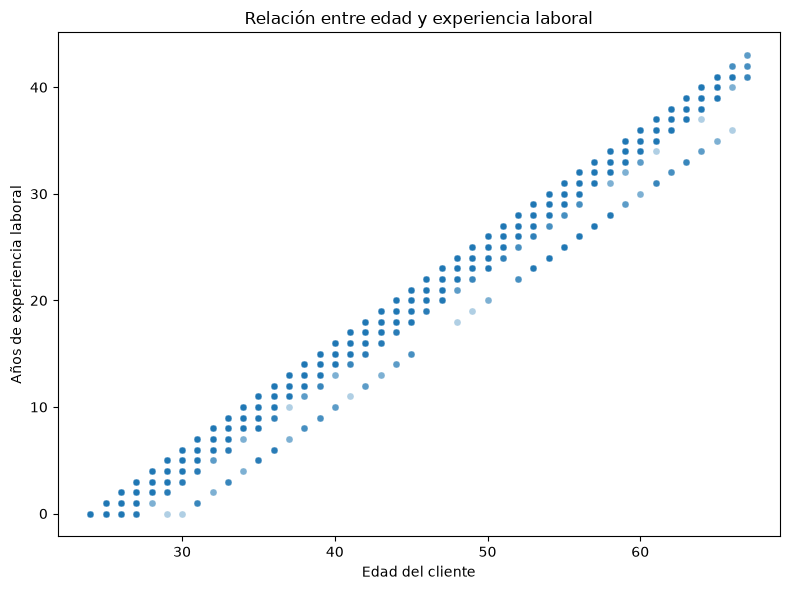

Correlación entre Age y Experience:
0.994


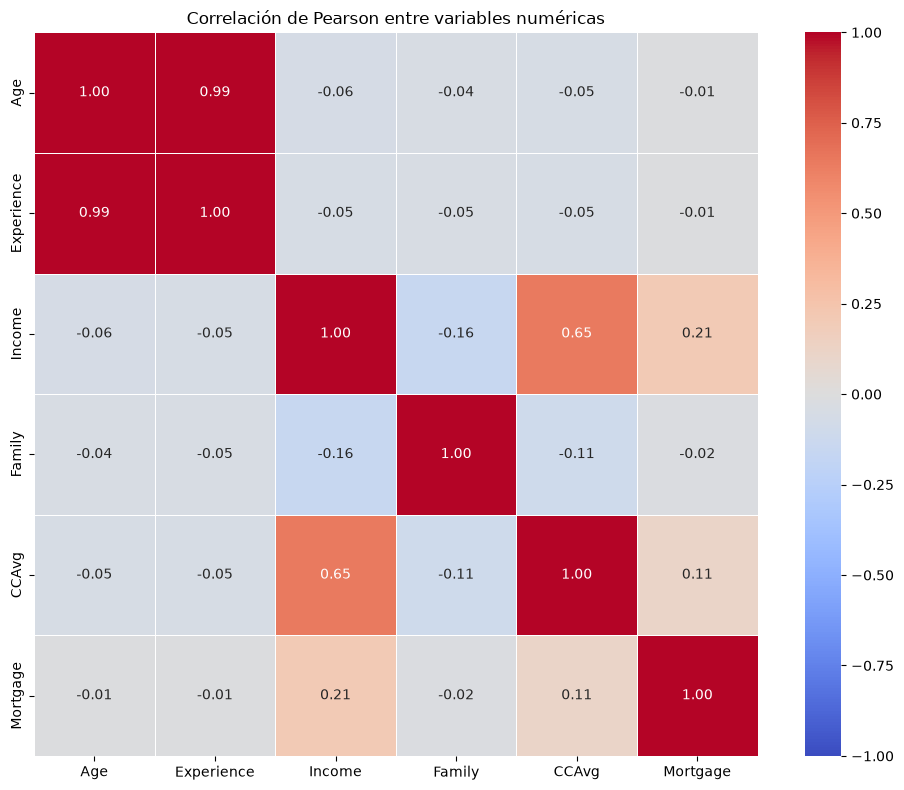

In [17]:
# ============================================================
# PROBLEMA 9
# Análisis de relaciones entre variables numéricas.
# ============================================================


# INCISO 1:


# de cada variable mediante un histograma.
matrizDispersion = sns.pairplot(
    data=loan_df[num_cols],
    diag_kind="hist",

    # Configuración de los puntos:
    # alpha controla la transparencia.
    # s controla el tamaño.
    plot_kws={
        "alpha": 0.25,
        "s": 15
    },

    # Tamaño de cada gráfica individual.
    height=2
)


# Agregamos un título general a la matriz.
matrizDispersion.fig.suptitle(
    "Matriz de dispersión de las variables numéricas",
    y=1.02
)

plt.show()

# INCISO 2:



fig, ax = plt.subplots(
    figsize=(8, 6)
)


# Eje Y -> años de experiencia laboral.
sns.scatterplot(
    data=loan_df,
    x="Age",
    y="Experience",
    alpha=0.35,
    s=25,
    ax=ax
)


ax.set_title(
    "Relación entre edad y experiencia laboral"
)

ax.set_xlabel(
    "Edad del cliente"
)

ax.set_ylabel(
    "Años de experiencia laboral"
)

plt.tight_layout()
plt.show()



# INCISO 3:


# Cerca de -1 -> relación negativa fuerte.
matrizCorrelacion = (
    loan_df[num_cols]
    .corr(method="pearson")
)

correlacionEdadExperiencia = (
    matrizCorrelacion.loc[
        "Age",
        "Experience"
    ]
)

print(
    "Correlación entre Age y Experience:"
)
print(
    f"{correlacionEdadExperiencia:.3f}"
)

# INCISO 4:

fig, ax = plt.subplots(
    figsize=(10, 8)
)


sns.heatmap(
    matrizCorrelacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax
)


ax.set_title(
    "Correlación de Pearson entre variables numéricas"
)

plt.tight_layout()
plt.show()

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


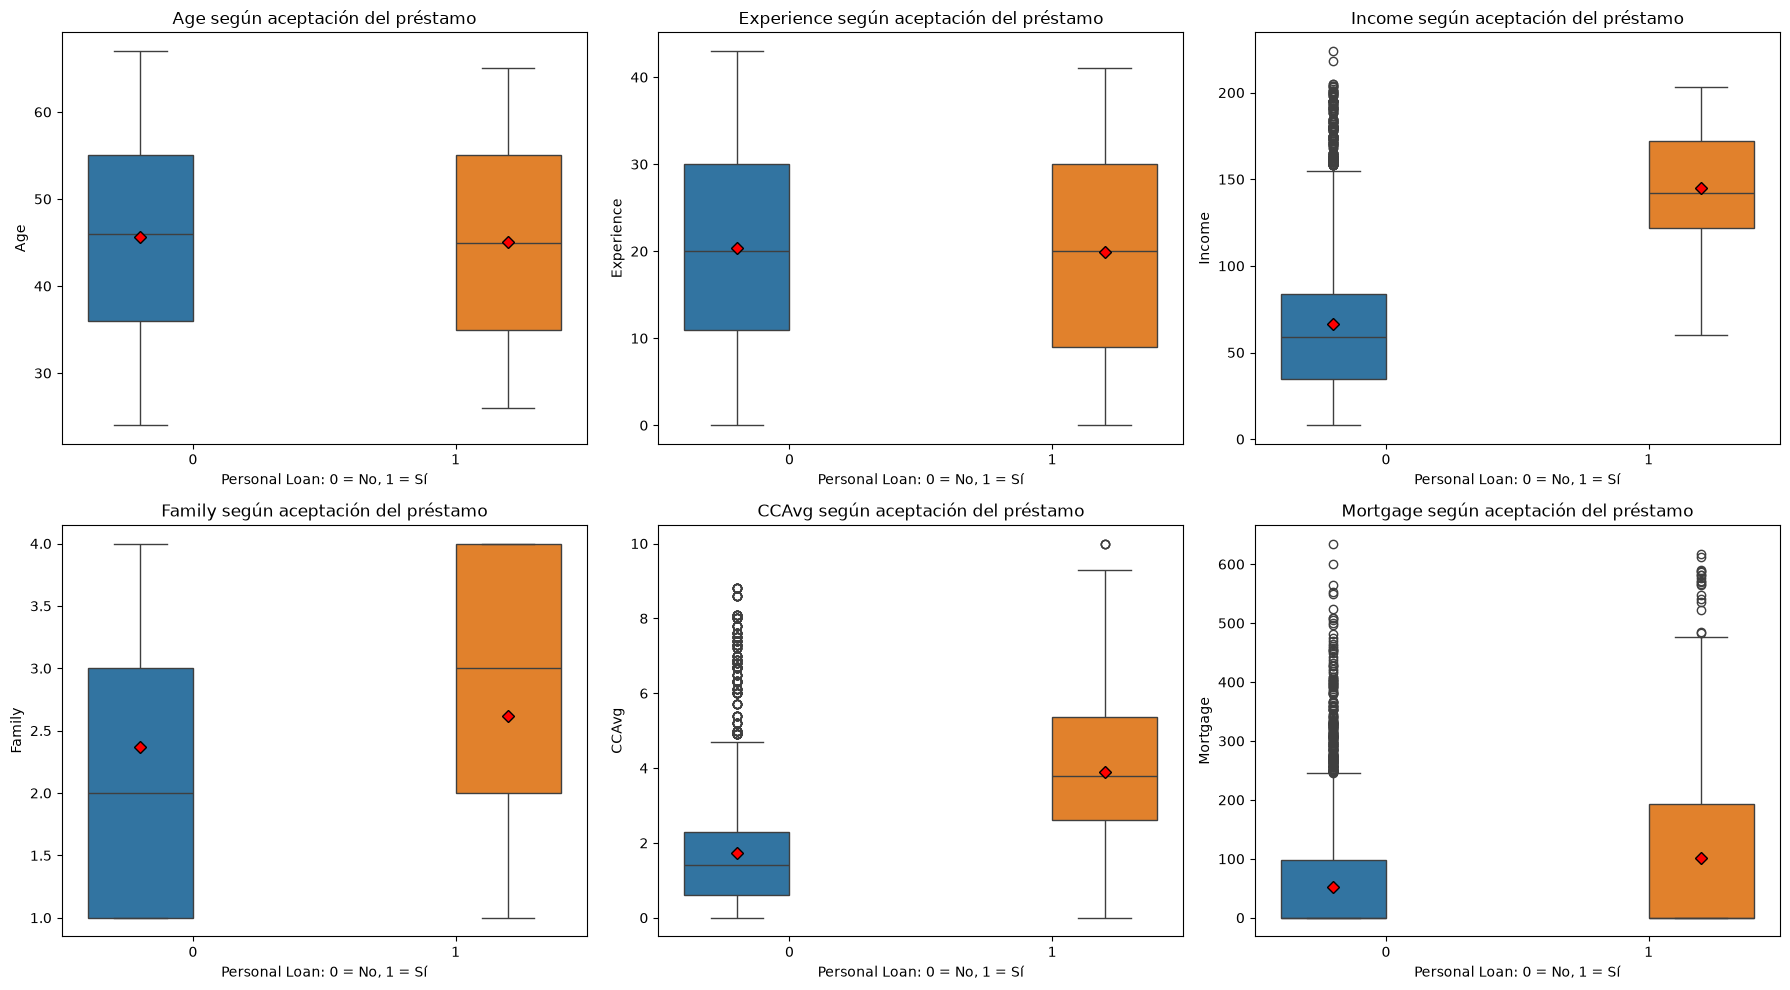

Promedios según aceptación del préstamo:


Personal Loan,0,1
Age,45.61,45.08
Experience,20.39,19.86
Income,66.22,144.71
Family,2.37,2.62
CCAvg,1.72,3.90
Mortgage,51.90,101.06



Medianas según aceptación del préstamo:


Personal Loan,0,1
Age,46.0,45.0
Experience,20.0,20.0
Income,59.0,142.0
Family,2.0,3.0
CCAvg,1.4,3.8
Mortgage,0.0,0.0


Variables categóricas que serán analizadas:
['Education', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


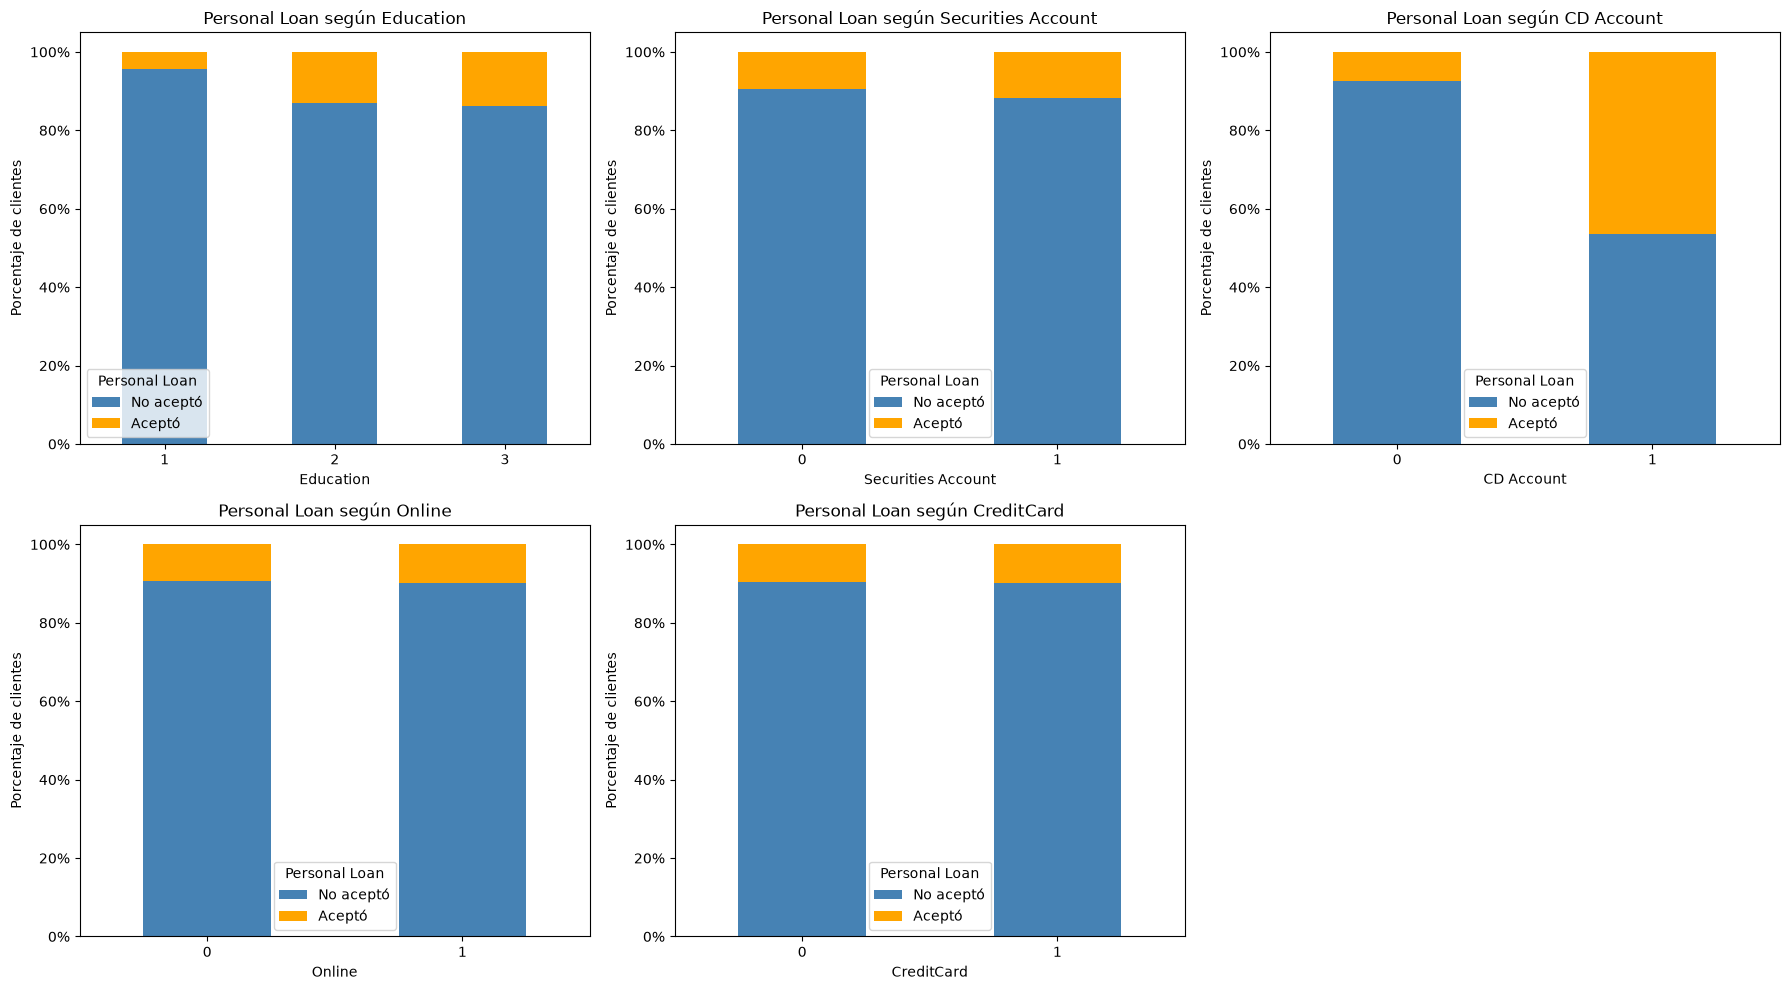


Porcentajes de Personal Loan según Education:


,No aceptó,Aceptó
Education,,
1,95.53,4.47
2,86.93,13.07
3,86.12,13.88



Porcentajes de Personal Loan según Securities Account:


,No aceptó,Aceptó
Securities Account,,
0,90.53,9.47
1,88.35,11.65



Porcentajes de Personal Loan según CD Account:


,No aceptó,Aceptó
CD Account,,
0,92.69,7.31
1,53.49,46.51



Porcentajes de Personal Loan según Online:


,No aceptó,Aceptó
Online,,
0,90.55,9.45
1,90.14,9.86



Porcentajes de Personal Loan según CreditCard:


,No aceptó,Aceptó
CreditCard,,
0,90.37,9.63
1,90.15,9.85


In [18]:
# Permite mostrar proporciones como porcentajes.
from matplotlib.ticker import PercentFormatter


# ============================================================
# INCISO 1:
# Comparar las variables numéricas con Personal Loan.
# ============================================================


# Creamos seis espacios, uno para cada variable numérica.
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18, 10)
)

axes = axes.flatten()


for variable, ax in zip(num_cols, axes):

    sns.boxplot(
        data=loan_df,
        x="Personal Loan",
        y=variable,

        # Da un color diferente a cada grupo.
        hue="Personal Loan",
        legend=False,

        # Agrega la media mediante un rombo rojo.
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "red",
            "markeredgecolor": "black",
            "markersize": 6
        },

        ax=ax
    )


    ax.set_title(
        f"{variable} según aceptación del préstamo"
    )

    ax.set_xlabel(
        "Personal Loan: 0 = No, 1 = Sí"
    )

    ax.set_ylabel(variable)


plt.tight_layout()
plt.show()





# Agrupamos los clientes según hayan aceptado o no
# el préstamo y calculamos el promedio de cada variable.
promediosPorPrestamo = (
    loan_df
    .groupby(
        "Personal Loan",
        observed=True
    )[num_cols]
    .mean()
    .T
)


# Calculamos también la mediana, que representa el valor
# central y se ve menos afectada por valores muy altos.
medianasPorPrestamo = (
    loan_df
    .groupby(
        "Personal Loan",
        observed=True
    )[num_cols]
    .median()
    .T
)


print(
    "Promedios según aceptación del préstamo:"
)

display(
    promediosPorPrestamo.round(2)
)


print(
    "\nMedianas según aceptación del préstamo:"
)

display(
    medianasPorPrestamo.round(2)
)



# INCISO 2:

# consigo misma.
variablesCategoricasAnalizar = [
    variable
    for variable in cat_cols
    if variable not in [
        "ZIP Code",
        "Personal Loan"
    ]
]


# Las variables restantes son:
#
# Education
# Securities Account
# CD Account
# Online
# CreditCard
print(
    "Variables categóricas que serán analizadas:"
)

print(
    variablesCategoricasAnalizar
)


# Creamos seis espacios.
# Utilizaremos cinco y eliminaremos el último.
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18, 10)
)

axes = axes.flatten()


# Este diccionario guardará las tablas de porcentajes.
tablasProporciones = {}


for variable, ax in zip(
    variablesCategoricasAnalizar,
    axes
):

    # crosstab() construye una tabla que cruza:
    
    # normalize="index" divide los resultados entre
    # el total de cada fila. De esta manera, cada
    # categoría suma 100%.
    tablaProporciones = pd.crosstab(
        index=loan_df[variable],
        columns=loan_df["Personal Loan"],
        normalize="index"
    )


    # Ordenamos las columnas como 0 y 1.
    tablaProporciones = (
        tablaProporciones
        .reindex(
            columns=[0, 1],
            fill_value=0
        )
    )


    # Reemplazamos los códigos por nombres comprensibles.
    tablaProporciones.columns = [
        "No aceptó",
        "Aceptó"
    ]


    # Guardamos una copia para mostrar los porcentajes
    # exactos después de las gráficas.
    tablasProporciones[variable] = (
        tablaProporciones.copy()
    )


    # stacked=True coloca los dos segmentos uno encima
    # del otro. Cada barra completa representa el 100%.
    tablaProporciones.plot(
        kind="bar",
        stacked=True,
        color=[
            "steelblue",
            "orange"
        ],
        ax=ax
    )


    ax.set_title(
        f"Personal Loan según {variable}"
    )

    ax.set_xlabel(variable)
    ax.set_ylabel("Porcentaje de clientes")

    # Convierte valores como 0.25 en 25%.
    ax.yaxis.set_major_formatter(
        PercentFormatter(xmax=1)
    )


    ax.tick_params(
        axis="x",
        rotation=0
    )


    ax.legend(
        title="Personal Loan"
    )

# Eliminamos el espacio que no se utilizó.
for ax in axes[
    len(variablesCategoricasAnalizar):
]:
    fig.delaxes(ax)


plt.tight_layout()
plt.show()


# TABLAS DE APOYO PARA LAS VARIABLES CATEGÓRICAS



for variable, tabla in tablasProporciones.items():

    print(
        f"\nPorcentajes de Personal Loan "
        f"según {variable}:"
    )

    # Las proporciones se multiplican por 100 para
    # mostrarlas como porcentajes.
    display(
        (tabla * 100).round(2)
    )

Los gráficos sugieren que Income, CCAvg y CD Account son las variables que mejor diferencian a los clientes que aceptaron el préstamo

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-SOL 5.6)], En este caso fue utilizado para comprender el planteamiento y concepto estadístico detras de cada uno de los problemas y guiarme con la solución de estos, según dado el caso y grado de dificultad. https://chat.openai.com/

---